# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Triyanti Aulia
- **Email:** triyantiaulia1501@gmail.com
- **ID Dicoding:** tryyaawlia

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Bagaimana pola rata-rata jumlah penyewaan sepeda berdasarkan jam dalam sehari dan jenis hari (hari kerja dan hari non-kerja) selama periode 2011–2012?
- **Pertanyaan 2:** Bagaimana perbedaan rata-rata jumlah penyewaan sepeda berdasarkan kondisi cuaca dan musim selama periode 2011–2012?
- **Pertanyaan 3:** Bagaimana perbandingan total jumlah dan persentase kontribusi penyewaan sepeda antara pengguna casual dan registered selama periode 2011–2012?

## Import Semua Packages/Library yang Digunakan

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df hour_df and day_df

In [45]:
hour_df = pd.read_csv('hour.csv')

hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [46]:
day_df = pd.read_csv('day.csv')
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:** (Opsional)
- Dataset hour_df berhasil dimuat dengan 17.379 baris dan 17 kolom yang berisi informasi penyewaan sepeda berdasarkan jam.
- Dataset day_df berhasil dimuat dengan 731 baris dan 16 kolom yang berisi informasi penyewaan sepeda berdasarkan hari.
- Kedua dataset memiliki variabel yang mendukung proses analisis, seperti waktu, kondisi cuaca, musim, dan jumlah penyewaan berdasarkan jenis pengguna.

### Assessing Data

#### Identifying hour_df and day_df problem

In [47]:
# Memeriksa tipe data hour_df
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  object 
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 2.3+ MB


In [48]:
# Memeriksa missing value hour_df
hour_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
hr,0
holiday,0
weekday,0
workingday,0
weathersit,0


In [49]:
# Memeriksa dan menampilkan data duplikat pada hour_df
print("Jumlah duplikasi: ", hour_df.duplicated().sum())

Jumlah duplikasi:  0


In [50]:
# Memeriksa parameter statistik pada hour_df
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [51]:
# Memeriksa tipe data day_df
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB


In [52]:
# Memeriksa missing value day_df
day_df.isna().sum()

,0
instant,0
dteday,0
season,0
yr,0
mnth,0
holiday,0
weekday,0
workingday,0
weathersit,0
temp,0


In [53]:
# Memeriksa dan menampilkan data duplikat pada day_df
print("Jumlah duplikasi: ", day_df.duplicated().sum())

Jumlah duplikasi:  0


In [54]:
# Memeriksa parameter statistik pada day_df
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [55]:
# Memeriksa Invalid Value pada hour_df

print("Invalid Value pada hour_df:")

print("season:", (~hour_df["season"].isin([1, 2, 3, 4])).sum())
print("weathersit:", (~hour_df["weathersit"].isin([1, 2, 3, 4])).sum())
print("hr:", (~hour_df["hr"].isin(range(24))).sum())


# Memeriksa Invalid Value pada day_df

print("\nInvalid Value pada day_df:")

print("season:", (~day_df["season"].isin([1, 2, 3, 4])).sum())
print("weathersit:", (~day_df["weathersit"].isin([1, 2, 3, 4])).sum())

Invalid Value pada hour_df:
season: 0
weathersit: 0
hr: 0

Invalid Value pada day_df:
season: 0
weathersit: 0


In [56]:
# Memeriksa Inconsistent Value pada hour_df

print("Inconsistent Value pada hour_df:")

print(
    (hour_df["cnt"] !=
     hour_df["casual"] + hour_df["registered"]).sum()
)

# Memeriksa Inconsistent Value pada day_df

print("\nInconsistent Value pada day_df:")

print(
    (day_df["cnt"] !=
     day_df["casual"] + day_df["registered"]).sum()
)


Inconsistent Value pada hour_df:
0

Inconsistent Value pada day_df:
0


In [57]:
# Memeriksa outlier pada kolom cnt di hour_df
Q1_hour = hour_df["cnt"].quantile(0.25)
Q3_hour = hour_df["cnt"].quantile(0.75)
IQR_hour = Q3_hour - Q1_hour

lower_hour = Q1_hour - 1.5 * IQR_hour
upper_hour = Q3_hour + 1.5 * IQR_hour

outlier_hour = hour_df[
    (hour_df["cnt"] < lower_hour) |
    (hour_df["cnt"] > upper_hour)
]

print("Jumlah outlier hour_df:", len(outlier_hour))

Jumlah outlier hour_df: 505


In [58]:
# Memeriksa outlier pada kolom cnt di day_df
Q1_day = day_df["cnt"].quantile(0.25)
Q3_day = day_df["cnt"].quantile(0.75)
IQR_day = Q3_day - Q1_day

lower_day = Q1_day - 1.5 * IQR_day
upper_day = Q3_day + 1.5 * IQR_day

outlier_day = day_df[
    (day_df["cnt"] < lower_day) |
    (day_df["cnt"] > upper_day)
]

print("Jumlah outlier day_df:", len(outlier_day))

Jumlah outlier day_df: 0


In [59]:
# Menampilkan 10 data yang terindikasi outlier dengan jumlah penyewaan tertinggi
outlier_hour[["dteday", "hr", "workingday", "cnt"]].sort_values(
    by="cnt",
    ascending=False
).head(10)


,dteday,hr,workingday,cnt
14773,2012-09-12,18,1,977
14964,2012-09-20,17,1,976
14748,2012-09-11,17,1,970
14725,2012-09-10,18,1,968
15084,2012-09-25,17,1,967
15780,2012-10-24,17,1,963
10622,2012-03-23,17,1,957
15108,2012-09-26,17,1,953
15444,2012-10-10,17,1,948
15588,2012-10-16,17,1,943


**Steps to Take:**
- Memeriksa struktur dan informasi dataset menggunakan fungsi info() untuk mengetahui jumlah data dan tipe data setiap kolom.
- Memeriksa missing values menggunakan kombinasi fungsi isna().sum() untuk mengetahui apakah terdapat nilai kosong atau missing value.
- Memeriksa data duplikat menggunakan kombinasi fungsi duplicated().sum() untuk mengetahui apakah terdapat baris data yang tercatat lebih dari satu kali.
- Memeriksa invalid values menggunakan fungsi isin() untuk memastikan nilai pada kolom season, weathersit, dan hr sesuai dengan rentang nilai yang telah ditentukan.
- Memeriksa inconsistent values dengan membandingkan nilai cnt terhadap hasil penjumlahan casual dan registered.
- Memeriksa parameter statistik menggunakan fungsi describe() untuk mengetahui distribusi dan rentang nilai pada kolom numerik.
- Memeriksa outlier pada kolom cnt menggunakan metode Interquartile Range (IQR) untuk mengetahui nilai yang berada di luar batas.
- Memeriksa beberapa data yang terindikasi outlier untuk mengevaluasi apakah nilai tersebut merupakan kondisi yang wajar atau kesalahan pencatatan data.

**Insight:** (Opsional)
- Dataset hour_df memiliki 17.379 baris dan 17 kolom, sedangkan day_df memiliki 731 baris dan 16 kolom.
- Kedua dataset tersebut tidak memiliki missing values maupun data duplikat setelah dilakukan pemeriksaan.
- Pemeriksaan invalid values menunjukkan bahwa nilai pada kolom season, weathersit, dan hr telah sesuai dengan rentang nilai yang ditentukan.
- Pemeriksaan inconsistent values menunjukkan bahwa jumlah penyewaan total (cnt) pada kedua dataset sudah sesuai dengan penjumlahan pengguna casual dan registered.
- Kolom dteday pada kedua dataset masih menggunakan tipe data object sehingga perlu diubah tipe datanya menjadi datetime.
- Pemeriksaan outlier menggunakan metode IQR menunjukkan terdapat 505 data yang terindikasi outlier pada kolom cnt di hour_df, sedangkan pada day_df tidak ditemukan outlier.
- Berdasarkan pemeriksaan terhadap 10 data yang terindikasi outlier dengan jumlah penyewaan tertinggi pada hour_df, seluruh data yang diperiksa terjadi pada hari kerja (workingday = 1) dan sebagian besar pada pukul 17.00–18.00.
- Berdasarkan statistik deskriptif, jumlah penyewaan sepeda pada dataset day_df memiliki rentang nilai 22 hingga 8.714, sedangkan pada dataset hour_df memiliki rentang nilai 1 hingga 977.

### Cleaning Data

#### Fixing hour_df and day_df problem

In [60]:
# Mengubah tipe data dteday menjadi datetime di kedua dataframe

hour_df["dteday"] = pd.to_datetime(hour_df["dteday"])
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

In [61]:
# Memeriksa tipe data dteday untuk memastikan perubahan telah berhasil di hour_df
hour_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

In [62]:
# Memeriksa tipe data dteday untuk memastikan perubahan telah berhasil di day_df
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [63]:
# Pemeriksaan kembali kondisi data setelah proses data cleaning

print("Missing Value hour_df:", hour_df.isna().sum().sum())
print("Duplicate hour_df:", hour_df.duplicated().sum())

print("\nMissing Value day_df:", day_df.isna().sum().sum())
print("Duplicate day_df:", day_df.duplicated().sum())

Missing Value hour_df: 0
Duplicate hour_df: 0

Missing Value day_df: 0
Duplicate day_df: 0


**Insight:** (Opsional)
- Kolom dteday pada dataset hour_df dan day_df berhasil diubah tipe datanya dari object menjadi datetime64[ns].
- Perubahan tipe data tersebut memungkinkan kolom tanggal digunakan untuk pengolahan dan analisis data berdasarkan waktu.
- Data yang terindikasi outlier pada hour_df tetap dipertahankan karena tidak ditemukan indikasi bahwa nilai tersebut merupakan kesalahan pencatatan atau human error.

## Exploratory Data Analysis (EDA)

### Explore hour_df and day_df

In [64]:
# Mengelompokkan rata-rata penyewaan berdasarkan jam dan jenis hari

hourly_rentals = hour_df.groupby(
    ["hr", "workingday"]
)["cnt"].mean().unstack()

hourly_rentals


workingday,0,1
hr,,
0,90.800000,36.786290
1,69.508696,16.552632
2,53.171053,8.683778
3,25.775330,4.942553
4,8.264317,5.429787
5,8.689189,24.913131
6,18.742358,102.500000
7,43.406926,290.612903
8,105.653680,477.006048


In [65]:
# Mencari jam dengan rata-rata penyewaan tertinggi

print("Hari Non-Kerja:")
print(hourly_rentals[0].idxmax())
print(hourly_rentals[0].max())

print("\nHari Kerja:")
print(hourly_rentals[1].idxmax())
print(hourly_rentals[1].max())

Hari Non-Kerja:
13
372.73160173160176

Hari Kerja:
17
525.2905811623247


In [66]:
# Mencari jam dengan rata-rata penyewaan terendah

print("Hari Non-Kerja:")
print("Jam:", hourly_rentals[0].idxmin())
print("Jumlah:", hourly_rentals[0].min())

print("\nHari Kerja:")
print("Jam:", hourly_rentals[1].idxmin())
print("Jumlah:", hourly_rentals[1].min())

Hari Non-Kerja:
Jam: 4
Jumlah: 8.26431718061674

Hari Kerja:
Jam: 3
Jumlah: 4.9425531914893615


In [67]:
# Menghitung rata-rata penyewaan berdasarkan kondisi cuaca

weather_rentals = day_df.groupby("weathersit")["cnt"].mean()
weather_rentals

,cnt
weathersit,
1,4876.786177
2,4035.862348
3,1803.285714


In [68]:
# Mencari kondisi cuaca dengan rata-rata penyewaan tertinggi dan terendah

print("Kondisi Cuaca:")
print("Tertinggi:", weather_rentals.idxmax())
print("Jumlah:", weather_rentals.max())

print("\nTerendah:", weather_rentals.idxmin())
print("Jumlah:", weather_rentals.min())

Kondisi Cuaca:
Tertinggi: 1
Jumlah: 4876.7861771058315

Terendah: 3
Jumlah: 1803.2857142857142


In [69]:
# Menghitung rata-rata penyewaan berdasarkan musim

season_rentals = day_df.groupby("season")["cnt"].mean()
season_rentals

,cnt
season,
1,2604.132597
2,4992.331522
3,5644.303191
4,4728.162921


In [70]:
# Mencari musim dengan rata-rata penyewaan tertinggi dan terendah

print("Musim:")
print("Tertinggi:", season_rentals.idxmax())
print("Jumlah:", season_rentals.max())

print("\nTerendah:", season_rentals.idxmin())
print("Jumlah:", season_rentals.min())


Musim:
Tertinggi: 3
Jumlah: 5644.303191489362

Terendah: 1
Jumlah: 2604.1325966850827


In [71]:
# Menghitung total penyewaan pengguna casual dan registered

total_casual = day_df["casual"].sum()
total_registered = day_df["registered"].sum()

print("Total penyewaan pengguna casual:", total_casual)
print("Total penyewaan pengguna registered:", total_registered)

Total penyewaan pengguna casual: 620017
Total penyewaan pengguna registered: 2672662


In [72]:
# Membandingkan total penyewaan pengguna

print("Perbandingan Penyewaan:")

print("Casual:", total_casual)
print("Registered:", total_registered)

if total_casual > total_registered:
    print("Pengguna casual memiliki jumlah penyewaan lebih tinggi.")
else:
    print("Pengguna registered memiliki jumlah penyewaan lebih tinggi.")

Perbandingan Penyewaan:
Casual: 620017
Registered: 2672662
Pengguna registered memiliki jumlah penyewaan lebih tinggi.


In [73]:
# Menghitung persentase kontribusi pengguna

total_rentals = day_df["cnt"].sum()

casual_percentage = (total_casual / total_rentals) * 100
registered_percentage = (total_registered / total_rentals) * 100

print("Kontribusi pengguna casual:", casual_percentage, "%")
print("Kontribusi pengguna registered:", registered_percentage, "%")

Kontribusi pengguna casual: 18.830168382645258 %
Kontribusi pengguna registered: 81.16983161735475 %


In [74]:
# Menghitung selisih jumlah penyewaan

rental_difference = total_registered - total_casual

print("Selisih penyewaan:", rental_difference)

Selisih penyewaan: 2052645


**Insight:** (Opsional)
- Pada hari kerja (workingday = 1), rata-rata penyewaan tertinggi terjadi pukul 17.00, yaitu sekitar 525 penyewaan. Sementara itu, pada hari non-kerja (workingday = 0), rata-rata penyewaan tertinggi terjadi pukul 13.00, yaitu sekitar 373 penyewaan.
- Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi terdapat pada kategori 1 (cerah atau sedikit berawan), yaitu sekitar 4.877 penyewaan. Rata-rata tersebut menurun menjadi sekitar 4.036 pada kategori 2 dan 1.803 pada kategori 3.
- Berdasarkan musim, musim gugur (fall) memiliki rata-rata penyewaan tertinggi, yaitu sekitar 5.644, sedangkan musim semi (spring) memiliki rata-rata terendah, yaitu sekitar 2.604.
- Dataset harian (day_df) hanya memiliki observasi pada kategori cuaca 1, 2, dan 3. Tidak terdapat observasi pada kategori cuaca 4 sehingga kategori tersebut tidak dapat dibandingkan.
- Total penyewaan oleh pengguna registered mencapai 2.672.662 atau 81,17%, sedangkan pengguna casual mencapai 620.017 atau 18,83%. Selisih jumlah penyewaan keduanya adalah 2.052.645.


## Visualization & Explanatory Analysis

### Pertanyaan 1:

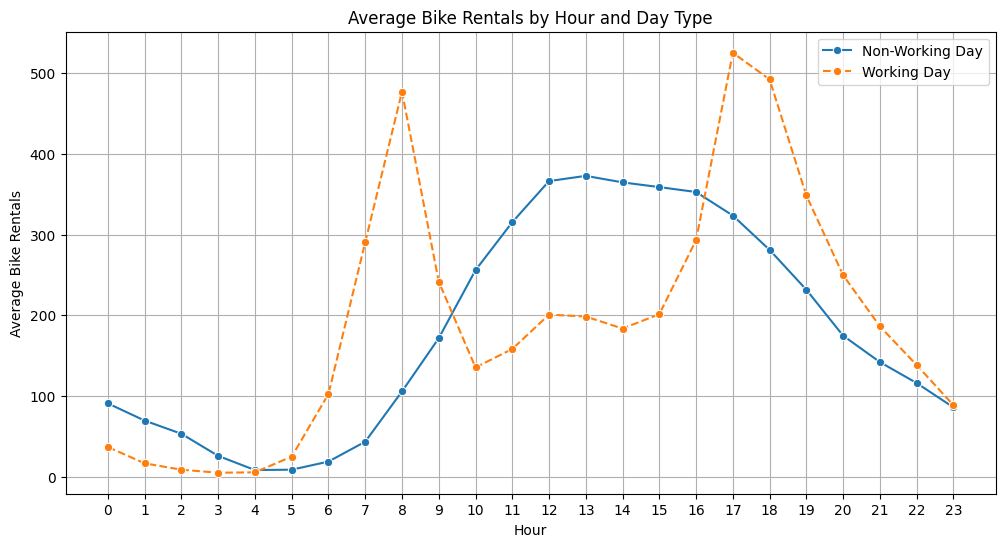

In [75]:
# Visualisasi pola penyewaan berdasarkan jam dan jenis hari

plt.figure(figsize=(12, 6))

sns.lineplot(
    x=hourly_rentals.index,
    y=hourly_rentals[0],
    label="Non-Working Day",
    marker="o"
)

sns.lineplot(
    x=hourly_rentals.index,
    y=hourly_rentals[1],
    label="Working Day",
    marker="o",
    linestyle="--"
)

plt.title("Average Bike Rentals by Hour and Day Type")
plt.xlabel("Hour")
plt.ylabel("Average Bike Rentals")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(True)
plt.show()

### Pertanyaan 2:

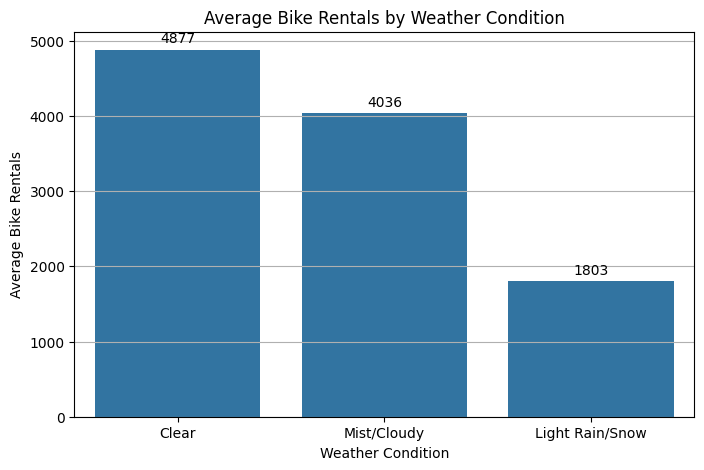

In [76]:
# Visualisasi penyewaan berdasarkan kondisi cuaca

plt.figure(figsize=(8, 5))

ax = sns.barplot(x=weather_rentals.index, y=weather_rentals.values)

plt.title("Average Bike Rentals by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Average Bike Rentals")
plt.xticks([0, 1, 2], ["Clear", "Mist/Cloudy", "Light Rain/Snow"])
plt.grid(axis="y")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.show()

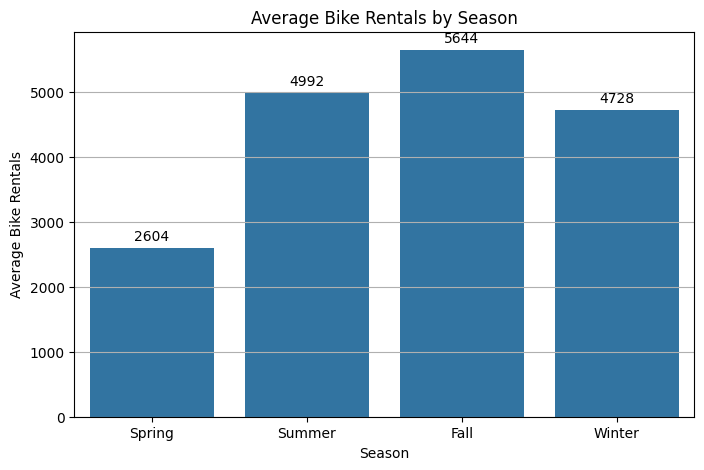

In [77]:
# Visualisasi penyewaan berdasarkan musim

plt.figure(figsize=(8, 5))

ax = sns.barplot(x=season_rentals.index, y=season_rentals.values)

plt.title("Average Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Bike Rentals")
plt.xticks([0, 1, 2, 3], ["Spring", "Summer", "Fall", "Winter"])
plt.grid(axis="y")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.show()

### Pertanyaan 3:

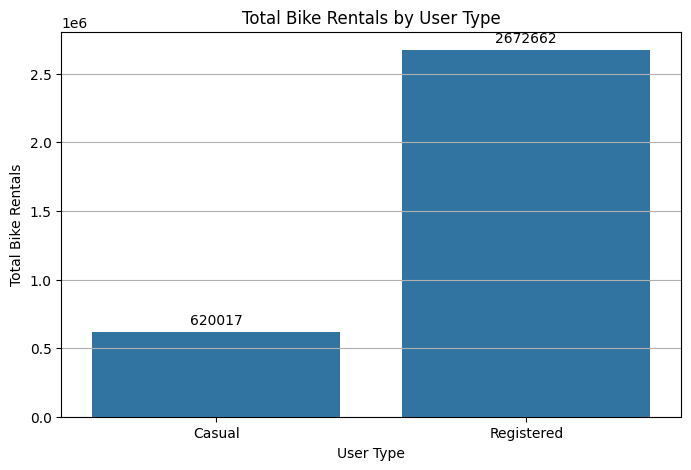

In [78]:
# Visualisasi penyewaan pengguna Casual dan Registered

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["Casual", "Registered"],
    y=[total_casual, total_registered]
)

plt.title("Total Bike Rentals by User Type")
plt.xlabel("User Type")
plt.ylabel("Total Bike Rentals")
plt.grid(axis="y")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.show()

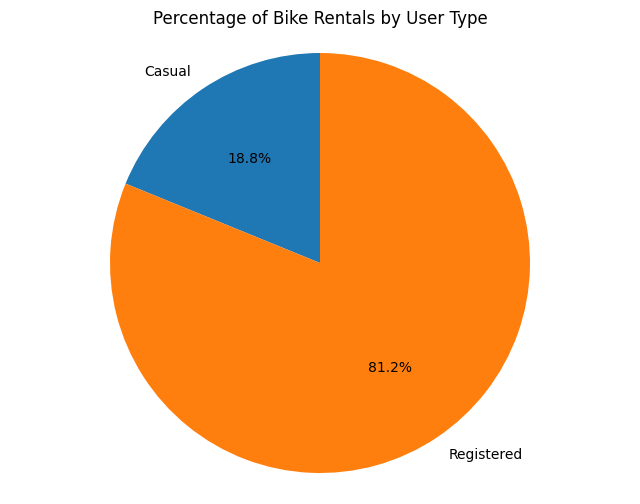

In [79]:
# Visualisasi persentase kontribusi pengguna Casual dan Registered

plt.figure(figsize=(8, 6))

plt.pie(
    [casual_percentage, registered_percentage],
    labels=["Casual", "Registered"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Bike Rentals by User Type")
plt.axis("equal")

plt.show()


**Insight:** (Opsional)
- Line chart menunjukkan perbedaan pola penyewaan berdasarkan jenis hari. Pada hari kerja, terlihat dua periode peningkatan aktivitas, yaitu pagi sekitar pukul 08.00 dan sore sekitar pukul 17.00. Sementara itu, pada hari non-kerja, penyewaan lebih terkonsentrasi pada siang hari, yaitu sekitar pukul 13.00.
- Bar chart kondisi cuaca memperlihatkan kecenderungan bahwa semakin kurang mendukung kondisi cuaca, semakin rendah rata-rata jumlah penyewaan sepeda.
- Bar chart musim menunjukkan bahwa aktivitas penyewaan berbeda sepanjang tahun, dengan musim gugur sebagai periode yang memiliki aktivitas penyewaan paling tinggi.
- Bar chart dan pie chart pengguna memperlihatkan dominasi pengguna registered dibandingkan pengguna casual, baik dari segi jumlah maupun proporsi penyewaan.

## Analisis Lanjutan (Opsional)

In [80]:
# Menganalisis kategori tingkat permintaan penyewaan sepeda (bike rental demand categorization)

# Membuat kategori permintaan
day_df["demand_category"] = pd.qcut(
    day_df["cnt"],
    q=3,
    labels=["Low Demand", "Medium Demand", "High Demand"]
)

In [81]:
# Menghitung jumlah hari pada setiap kategori

day_df["demand_category"].value_counts()

,count
demand_category,
Low Demand,244
Medium Demand,244
High Demand,243


In [82]:
# Menganalisis karakteristik setiap kategori

demand_analysis = day_df.groupby("demand_category", observed=True)[
    ["cnt", "casual", "registered"]
].mean()

demand_analysis

,cnt,casual,registered
demand_category,,,
Low Demand,2312.065574,333.381148,1978.684426
Medium Demand,4522.225410,842.963115,3679.262295
High Demand,6687.703704,1370.325103,5317.378601


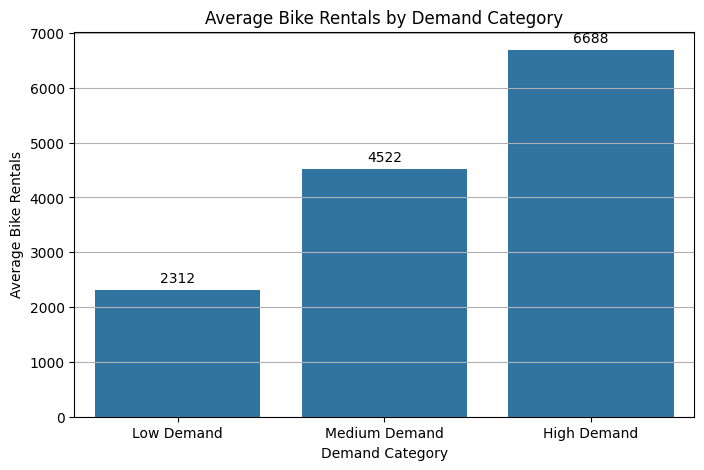

In [83]:
# Visualisasi rata-rata jumlah penyewaan sepeda berdasarkan kategori permintaan

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=demand_analysis.reset_index(),
    x="demand_category",
    y="cnt"
)

plt.title("Average Bike Rentals by Demand Category")
plt.xlabel("Demand Category")
plt.ylabel("Average Bike Rentals")
plt.grid(axis="y")

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.show()

In [84]:
hour_df.to_csv("main_data.csv", index=False)

**Insight:** (Opsional)
- Low Demand: kategori ini memiliki rata-rata penyewaan sekitar 2.312 sepeda per hari dengan rata-rata pengguna casual sebanyak 333 dan registered sebanyak 1.979.
- Medium Demand: kategori ini memiliki rata-rata penyewaan sekitar 4.522 sepeda per hari, dengan rata-rata pengguna casual sebanyak 843 dan registered sebanyak 3.679.
- High Demand: kategori ini memiliki rata-rata penyewaan tertinggi, yaitu sekitar 6.688 sepeda per hari, dengan rata-rata pengguna casual sebanyak 1.370 dan registered sebanyak 5.317.
- Pada seluruh kategori permintaan, rata-rata penyewaan oleh pengguna registered selalu lebih tinggi dibandingkan pengguna casual. Hal ini menunjukkan bahwa pengguna registered merupakan kontributor utama dalam aktivitas penyewaan sepeda.

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pola penyewaan sepeda berbeda antara hari kerja dan hari non-kerja. Pada hari kerja, rata-rata penyewaan tertinggi terjadi pukul 17.00 dengan sekitar 525 penyewaan, sedangkan pada hari non-kerja puncaknya terjadi pukul 13.00 dengan sekitar 373 penyewaan. Hal ini menunjukkan bahwa aktivitas penyewaan pada hari kerja cenderung meningkat pada jam berangkat dan pulang kerja, sedangkan pada hari non-kerja lebih terkonsentrasi pada siang hari.
- **Conclusion pertanyaan 2:** Kondisi cuaca dan musim menunjukkan perbedaan rata-rata penyewaan sepeda. Cuaca cerah memiliki rata-rata penyewaan tertinggi sekitar 4.877 penyewaan, sedangkan hujan ringan atau salju ringan memiliki rata-rata terendah sekitar 1.803 penyewaan. Berdasarkan musim, musim gugur memiliki rata-rata penyewaan tertinggi sekitar 5.644 penyewaan, sedangkan musim semi memiliki rata-rata terendah sekitar 2.604 penyewaan.
- **Conclusion pertanyaan 3:** Pengguna registered mendominasi aktivitas penyewaan sepeda dengan total 2.672.662 penyewaan atau sekitar 81,17% dari keseluruhan penyewaan. Sementara itu, pengguna casual menyumbang 620.017 penyewaan atau sekitar 18,83%. Hal ini menunjukkan bahwa sebagian besar aktivitas penyewaan berasal dari pengguna yang telah terdaftar.

**Rekomendasi Action Item:**
- Mengoptimalkan distribusi sepeda berdasarkan pola waktu penyewaan. Pengelola dapat meningkatkan kesiapan dan ketersediaan sepeda pada periode dengan permintaan tinggi, yaitu pukul 08.00 dan 17.00 pada hari kerja serta pukul 13.00 pada hari non-kerja. Penyesuaian ini bertujuan untuk mengantisipasi peningkatan permintaan dan mengurangi risiko kekurangan sepeda.
- Menyesuaikan perencanaan operasional berdasarkan musim dan kondisi cuaca. Pengelola dapat mempersiapkan ketersediaan sepeda dan kebutuhan operasional secara lebih optimal menjelang musim gugur yang memiliki rata-rata penyewaan tertinggi. Selain itu, ketika kondisi cuaca kurang mendukung, pengelola dapat menyesuaikan kebutuhan operasional berdasarkan perkiraan penurunan permintaan.
- Mempertahankan loyalitas pengguna registered. Mengingat pengguna registered mendominasi aktivitas penyewaan, pengelola dapat menyediakan program loyalitas, seperti poin reward, keuntungan khusus keanggotaan, atau diskon bagi pengguna aktif untuk mendorong penggunaan layanan secara berkelanjutan.
- Meningkatkan perubahan pengguna casual menjadi registered. Pengelola dapat menawarkan promosi pendaftaran keanggotaan, seperti potongan harga untuk pendaftaran pertama atau keuntungan khusus bagi pengguna yang beralih menjadi anggota. Strategi ini diharapkan dapat meningkatkan jumlah pengguna terdaftar dan memperkuat loyalitas pengguna.